<a href="https://colab.research.google.com/github/Ali20292/colon-cancer-gene-markers/blob/main/colon_mRNA-seq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A Machine Learning Approach for Identifying Gene Markers in Colon Cancer
Bachelor thesis, German University in Cairo (Media Engineering and Technology).

Pipeline: TCGA-COAD RNA-seq (517 samples) → DESeq2 differential expression → DAVID / GOplot enrichment → LASSO, SVM and Random Forest classifiers.

## 0. Setup
Mount Google Drive (the data lives in `MyDrive/colon/`), load rpy2 and install the R packages.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/colon/colon data set.zip'
extract_path = '/content/tcga_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Done!")

Done!


In [ ]:
import shutil

shutil.copy(
    '/content/drive/MyDrive/colon/gdc_sample_sheet.2026-04-16.tsv',
    '/content/gdc_sample_sheet.tsv'
)
print("Done!")

Done!


In [ ]:
!pip install -q rpy2

In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R
if (!require("BiocManager", quietly = TRUE)) install.packages("BiocManager")
BiocManager::install(c("DESeq2", "org.Hs.eg.db", "vsn", "ComplexHeatmap", "EnhancedVolcano"), update = FALSE, ask = FALSE)
install.packages(c("readr", "plotly", "GOplot", "RColorBrewer", "ggplot2", "caret", "e1071", "randomForest", "glmnet", "pROC", "ROSE", "MLmetrics"))

## 1. Data loading
Reads the 517 STAR gene-count files, keeps protein-coding genes, merges duplicate gene symbols and attaches tumor/normal labels from the GDC sample sheet.

In [ ]:
%%R
library(readr)
library(DESeq2)
library(org.Hs.eg.db)
library(vsn)

print("All libraries loaded successfully!")

[1] "All libraries loaded successfully!"


Loading required package: AnnotationDbi



In [ ]:
%%R
data.path <- "/content/tcga_data"
pheno.path <- "/content/gdc_sample_sheet.tsv"

pheno <- read.delim(pheno.path, header=TRUE, sep="\t")

dim(pheno)
head(pheno)

                               File.ID
1 ff710149-0fc6-464a-93cb-e3b9bdcf3525
2 9e159c7f-39ac-4051-83db-983d3aeba5a9
3 a11f48e9-775c-420a-99d1-04b1a5bc1419
4 2063302d-2b9d-4550-8426-fb64f5ea89d1
5 a44fa392-54c2-48b0-b342-e3e9e8340a8f
6 a06c89f2-be32-4102-b126-45dcfd364dae
                                                                    File.Name
1 dfb9c45f-cb52-4e36-b663-1a9e8c7c0b47.rna_seq.augmented_star_gene_counts.tsv
2 d9780581-dfca-4e83-9bb4-4836f22d910e.rna_seq.augmented_star_gene_counts.tsv
3 ddc4c764-f1da-46db-89d9-8ad7e253a09f.rna_seq.augmented_star_gene_counts.tsv
4 eb67b977-b299-4bbc-b3f6-25d516473405.rna_seq.augmented_star_gene_counts.tsv
5 db087000-74fa-4044-812f-01842b99f448.rna_seq.augmented_star_gene_counts.tsv
6 c4464d1a-4513-44af-a555-68cd0ca584b1.rna_seq.augmented_star_gene_counts.tsv
            Data.Category                      Data.Type Project.ID
1 Transcriptome Profiling Gene Expression Quantification  TCGA-COAD
2 Transcriptome Profiling Gene Expression Qua

In [ ]:
%%R
library(readr)
library(org.Hs.eg.db)
library(vsn)
library(DESeq2)

data.path <- "/content/tcga_data"
pheno.path <- "/content/gdc_sample_sheet.tsv"

files <- list.files(path=data.path, recursive=T, pattern="tsv")
files <- files[!grepl("logs", files)]

file <- files[1]
filepath <- file.path(data.path, files[1])
colnames <- unlist(strsplit(readLines(filepath, n=2)[2], "\t"))

temp <- read.table(filepath, header=F, skip=6)
names(temp) <- colnames
genotype_mapper <- temp[, c(2,3)]

exp <- temp[temp$gene_type == "protein_coding", c(1,2)]

for(i in 1:length(files))
{
  file <- files[i]
  file.id <- strsplit(file, "/")[[1]][1]
  filepath <- file.path(data.path, files[i])

  temp <- read.table(filepath, header=F, skip=6)
  temp <- temp[temp[,3] == "protein_coding", ]

  exp=cbind(exp, temp[,4])
  colnames(exp)[dim(exp)[2]]=file.id

  x=duplicated(exp$gene_name)

  if(i %% 50 == 0) cat("Processed", i, "/", length(files), "\n")
}

cat("Done!\n")

Processed 50 / 517 
Processed 100 / 517 
Processed 150 / 517 
Processed 200 / 517 
Processed 250 / 517 
Processed 300 / 517 
Processed 350 / 517 
Processed 400 / 517 
Processed 450 / 517 
Processed 500 / 517 
Done!


In [ ]:
%%R
exp.data=exp[,3:dim(exp)[2]]
exp.data=apply(exp.data,2,as.numeric)

In [ ]:
%%R
exp.data.agg=aggregate(exp.data,list(exp$gene_name),FUN=mean)
genes=exp.data.agg$Group.1
exp.data.agg=exp.data.agg[-1]
exp.data.agg=apply(exp.data.agg,2,as.numeric)
exp.data.agg=round(exp.data.agg)
rownames(exp.data.agg)=genes
file.ids=colnames(exp.data.agg)

In [ ]:
%%R
pheno <- read.delim(pheno.path, sep="\t", header=TRUE)
head(pheno)

                               File.ID
1 ff710149-0fc6-464a-93cb-e3b9bdcf3525
2 9e159c7f-39ac-4051-83db-983d3aeba5a9
3 a11f48e9-775c-420a-99d1-04b1a5bc1419
4 2063302d-2b9d-4550-8426-fb64f5ea89d1
5 a44fa392-54c2-48b0-b342-e3e9e8340a8f
6 a06c89f2-be32-4102-b126-45dcfd364dae
                                                                    File.Name
1 dfb9c45f-cb52-4e36-b663-1a9e8c7c0b47.rna_seq.augmented_star_gene_counts.tsv
2 d9780581-dfca-4e83-9bb4-4836f22d910e.rna_seq.augmented_star_gene_counts.tsv
3 ddc4c764-f1da-46db-89d9-8ad7e253a09f.rna_seq.augmented_star_gene_counts.tsv
4 eb67b977-b299-4bbc-b3f6-25d516473405.rna_seq.augmented_star_gene_counts.tsv
5 db087000-74fa-4044-812f-01842b99f448.rna_seq.augmented_star_gene_counts.tsv
6 c4464d1a-4513-44af-a555-68cd0ca584b1.rna_seq.augmented_star_gene_counts.tsv
            Data.Category                      Data.Type Project.ID
1 Transcriptome Profiling Gene Expression Quantification  TCGA-COAD
2 Transcriptome Profiling Gene Expression Qua

In [ ]:
%%R
file.ids.pheno=pheno$File.ID
index.files=match(file.ids,file.ids.pheno)
colnames(exp.data.agg)=pheno$Sample.ID [index.files]
save(exp.data.agg,genotype_mapper,pheno,file="MODA_RNA_Seq.RDATA")

## 2. Exploration and filtering
Distribution checks, PCA of all genes, and removal of the 10% least variable genes.

In [ ]:
%%R
cat("Expression matrix dimensions:\n")
cat("Genes:", nrow(exp.data.agg), "\n")
cat("Samples:", ncol(exp.data.agg), "\n")

cat("\nSample types:\n")
print(table(pheno$Tissue.Type))

cat("\nAny NAs:", sum(is.na(exp.data.agg)), "\n")

Expression matrix dimensions:
Genes: 19938 
Samples: 517 

Sample types:

Normal  Tumor 
    41    476 

Any NAs: 0 


In [ ]:
%%R
png("/content/drive/MyDrive/colon/box_plot.png", width=1200, height=800, res=150)
par(mfrow=c(1,1))
boxplot(log2(exp.data.agg + 1)[, 1:20],
        las=2,
        col="lightblue",
        main="Gene Expression Distribution (first 20 samples)",
        ylab="log2(counts + 1)",
        cex.axis=0.6)
dev.off()
cat("Saved!\n")

Saved!


In [ ]:
%%R
png("/content/drive/MyDrive/colon/histogram.png", width=1200, height=800, res=150)
hist(log2(exp.data.agg + 1),
     main="Expression Distribution",
     xlab="log2(counts + 1)",
     col="lightblue",
     breaks=50)
dev.off()
cat("Saved!\n")

Saved!


In [ ]:
%%R
png("/content/drive/MyDrive/colon/pca_allgenes.png", width=1200, height=800, res=150)
exp.for.pca <- exp.data.agg[apply(exp.data.agg, 1, var) > 0, ]
cat("Genes used for PCA:", nrow(exp.for.pca), "\n")

pca <- prcomp(t(log2(exp.for.pca + 1)), scale.=FALSE)

colors <- ifelse(pheno$Tissue.Type[match(colnames(exp.data.agg),
                 pheno$Sample.ID)] == "Tumor", "red", "blue")

plot(pca$x[,1], pca$x[,2],
     col=colors,
     pch=16,
     main="PCA Plot",
     xlab=paste0("PC1 (", round(summary(pca)$importance[2,1]*100, 1), "%)"),
     ylab=paste0("PC2 (", round(summary(pca)$importance[2,2]*100, 1), "%)"))

legend("topright",
       legend=c("Tumor", "Normal"),
       col=c("red", "blue"),
       pch=16)
dev.off()
cat("Saved!\n")

Genes used for PCA: 19486 
Saved!


In [ ]:
%%R
gene.var <- apply(exp.data.agg, 1, var)

threshold <- quantile(gene.var, 0.10)

exp.data.agg <- exp.data.agg[gene.var > threshold, ]

cat("Genes before filtering:", length(gene.var), "\n")
cat("Genes after removing least 10% variable:", nrow(exp.data.agg), "\n")

Genes before filtering: 19938 
Genes after removing least 10% variable: 17944 


## 3. Differential expression (DESeq2)
Tumor vs normal; DEGs are genes with adjusted p < 0.05 and |log2 fold change| > 1.

In [ ]:
%%R
table(pheno$Tissue.Type)
cond1="Normal"
cond2="Tumor"
dds=DESeqDataSetFromMatrix(countData=exp.data.agg,colData=pheno,design=~Tissue.Type)
dds.run=DESeq(dds)
res=results(dds.run,contrast=c("Tissue.Type",cond1,cond2))

converting counts to integer mode
estimating size factors
estimating dispersions
gene-wise dispersion estimates
mean-dispersion relationship
final dispersion estimates
fitting model and testing
-- replacing outliers and refitting for 2363 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)
estimating dispersions
fitting model and testing
In addition: Warning message:
In DESeqDataSet(se, design = design, ignoreRank) :
  some variables in design formula are characters, converting to factors


In [ ]:
%%R
res=res[complete.cases(res),]
summary(res)


out of 17596 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 32, 0.18%
LFC < 0 (down)     : 176, 1%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 1)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results




out of 17596 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 32, 0.18%
LFC < 0 (down)     : 176, 1%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 1)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



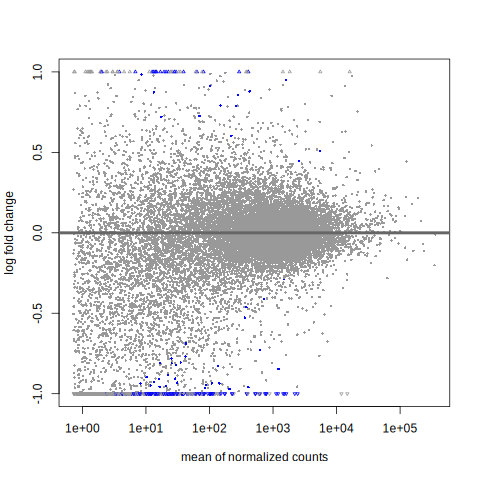

In [ ]:
%%R
res.df=as.data.frame(res)
write.table(res.df,file="res.txt")
plotMA(res,ylim=c(-1,1))
summary(res)

In [ ]:
%%R
res.degs=res.df[res.df$padj<0.05&abs(res.df$log2FoldChange)>log2(2),]
res.degs=res.degs[order(res.degs$padj),]
degs.genes=rownames(res.degs)

In [ ]:
%%R
write.table(degs.genes,file="degs_colon.txt",quote=F,col.names=F,)
ntd=normTransform(dds)
exp.norm=assay(ntd)
degs.exp=exp.norm[degs.genes,]

## 4. DEG visualisation
Heatmap, PCA and volcano plot of the differentially expressed genes. Plots are saved as PNG files to `MyDrive/colon/`.

In [ ]:
%%R
cat("Number of DEGs:", length(degs.genes), "\n")
cat("degs.exp dimensions:", nrow(degs.exp), "x", ncol(degs.exp), "\n")
cat("First few degs.genes:\n")
print(head(degs.genes))
cat("First few rownames of degs.exp:\n")
print(head(rownames(degs.exp)))

Number of DEGs: 92 
degs.exp dimensions: 92 x 517 
First few degs.genes:
[1] "AQP5"   "IGF2"   "ZNF556" "NOTUM"  "OPRD1"  "PADI3" 
First few rownames of degs.exp:
[1] "AQP5"   "IGF2"   "ZNF556" "NOTUM"  "OPRD1"  "PADI3" 


In [ ]:
%%R
suppressPackageStartupMessages(library(ComplexHeatmap))

top100.exp <- degs.exp[1:90, ]

top100.scaled <- t(scale(t(top100.exp)))

sample.type <- pheno$Tissue.Type[match(colnames(top100.scaled), pheno$Sample.ID)]
ha <- HeatmapAnnotation(
    Type = sample.type,
    col = list(Type = c("Tumor" = "red", "Normal" = "blue"))
)

png("/content/drive/MyDrive/colon/heatmap.png", width=1200, height=800, res=150)
draw(Heatmap(top100.scaled,
        name = "Expression",
        top_annotation = ha,
        show_row_names = TRUE,
        show_column_names = FALSE,
        cluster_rows = TRUE,
        cluster_columns = TRUE,
        row_names_gp = gpar(fontsize = 7),
        column_title = "Top 90 DEGs Heatmap",
        col = colorRampPalette(c("blue", "white", "red"))(100)))
dev.off()
cat("Heatmap saved!\n")

Heatmap saved!


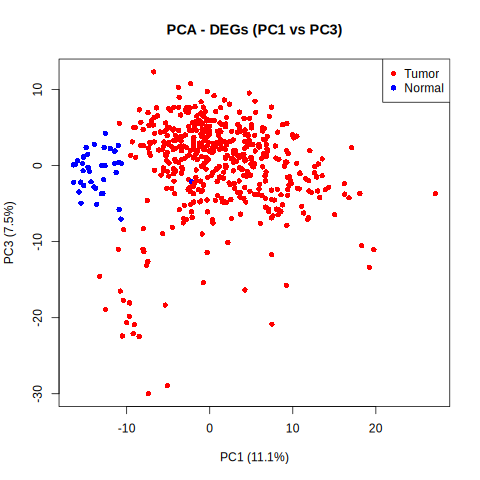

In [ ]:
%%R
pca.degs <- prcomp(t(degs.exp), scale.=FALSE)

pc1.var <- round(summary(pca.degs)$importance[2,1]*100, 1)
pc2.var <- round(summary(pca.degs)$importance[2,2]*100, 1)
pc3.var <- round(summary(pca.degs)$importance[2,3]*100, 1)

sample.type <- pheno$Tissue.Type[match(colnames(degs.exp), pheno$Sample.ID)]
colors <- ifelse(sample.type == "Tumor", "red", "blue")

pca.df <- data.frame(
    PC1 = pca.degs$x[,1],
    PC2 = pca.degs$x[,2],
    PC3 = pca.degs$x[,3],
    Type = sample.type
)

plot(pca.df$PC1, pca.df$PC2,
     col = colors, pch = 16,
     main = "PCA - DEGs (PC1 vs PC2)",
     xlab = paste0("PC1 (", pc1.var, "%)"),
     ylab = paste0("PC2 (", pc2.var, "%)"))
legend("topright", legend=c("Tumor","Normal"), col=c("red","blue"), pch=16)

plot(pca.df$PC1, pca.df$PC3,
     col = colors, pch = 16,
     main = "PCA - DEGs (PC1 vs PC3)",
     xlab = paste0("PC1 (", pc1.var, "%)"),
     ylab = paste0("PC3 (", pc3.var, "%)"))
legend("topright", legend=c("Tumor","Normal"), col=c("red","blue"), pch=16)

In [ ]:
%%R
suppressPackageStartupMessages(library(EnhancedVolcano))

volcano.plot <- EnhancedVolcano(res.df,
    lab = rownames(res.df),
    x = "log2FoldChange",
    y = "padj",
    title = "Tumor vs Normal - Colon Cancer",
    subtitle = paste0("Total DEGs: ", nrow(res.degs)),
    pCutoff = 0.05,
    FCcutoff = log2(2),
    pointSize = 2,
    labSize = 3,
    col = c("grey", "blue", "green", "red"),
    legendPosition = "right")

png("/content/drive/MyDrive/colon/volcano.png", width=1200, height=800, res=150)
print(volcano.plot)
dev.off()

cat("Volcano plot saved!\n")

Volcano plot saved!


In addition: Warning messages:
1: Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the EnhancedVolcano package.
  Please report the issue to the authors.
This warning is displayed once per session.
Call `lifecycle::last_lifecycle_warnings()` to see where this warning was
generated. 
2: The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the EnhancedVolcano package.
  Please report the issue to the authors.
This warning is displayed once per session.
Call `lifecycle::last_lifecycle_warnings()` to see where this warning was
generated. 


## 5. Enrichment analysis
The DEG list is exported and run through DAVID; the significant GO terms (Benjamini < 0.05) are plotted with GOplot. `DAVIDChart.csv` is the DAVID export.

In [ ]:
%%R
write.table(degs.genes,
            file="/content/drive/MyDrive/colon/degs_colon.txt",
            quote=FALSE,
            col.names=FALSE,
            row.names=FALSE)

cat("Total DEGs exported:", length(degs.genes), "\n")
cat("File saved to Google Drive!\n")
cat("\nNow go to:\n")
cat("- DAVID: https://david.ncifcrf.gov\n")
cat("- Enrichr: https://maayanlab.cloud/Enrichr\n")
cat("- GeneTrail: https://genetrail.bioinf.uni-sb.de\n")

Total DEGs exported: 92 
File saved to Google Drive!

Now go to:
- DAVID: https://david.ncifcrf.gov
- Enrichr: https://maayanlab.cloud/Enrichr
- GeneTrail: https://genetrail.bioinf.uni-sb.de


In [ ]:
%%R
david <- read.csv("/content/drive/MyDrive/colon/DAVIDChart.csv")
head(david)
cat("Columns:", names(david), "\n")

Columns: Category Term Count List.Total Pop.Hits Pop.Total P.Value Benjamini Fold.Enrichment Bonferroni FDR Fisher.Exact User.Ids 


Significant terms: 7 
GO terms: 4 
GO plot saved to Google Drive!


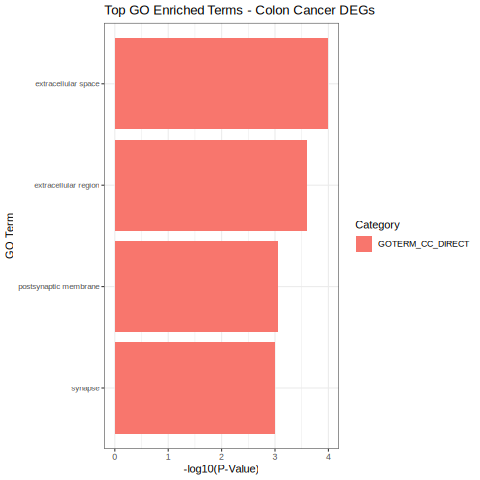

In [ ]:
%%R
library(GOplot)
library(ggplot2)

david.sig <- david[david$Benjamini < 0.05, ]
cat("Significant terms:", nrow(david.sig), "\n")

david.go <- david.sig[grepl("GOTERM", david.sig$Category), ]
cat("GO terms:", nrow(david.go), "\n")

david.go$Term <- gsub("GO:\\d+~", "", david.go$Term)

david.top20 <- david.go[order(david.go$P.Value), ][1:min(20, nrow(david.go)), ]

go.plot <- ggplot(david.top20,
       aes(x = reorder(Term, -P.Value),
           y = -log10(P.Value),
           fill = Category)) +
  geom_bar(stat = "identity") +
  coord_flip() +
  theme_bw() +
  labs(title = "Top GO Enriched Terms - Colon Cancer DEGs",
       x = "GO Term",
       y = "-log10(P-Value)") +
  theme(axis.text.y = element_text(size = 8))

print(go.plot)

png("/content/drive/MyDrive/colon/GO_enrichment.png", width=1400, height=900, res=150)
print(go.plot)
dev.off()
cat("GO plot saved to Google Drive!\n")

In [ ]:
%%R
library(GOplot)

david.sig <- david[david$Benjamini < 0.05 & grepl("GOTERM", david$Category), ]

david.sig$Term <- gsub("GO:\\d+~", "", david.sig$Term)

cat("Significant GO terms:", nrow(david.sig), "\n")
print(head(david.sig[, c("Category", "Term", "Count", "P.Value", "Benjamini", "Fold.Enrichment")]))

Significant GO terms: 4 
          Category                  Term Count  P.Value Benjamini
2 GOTERM_CC_DIRECT   extracellular space    21 0.000101    0.0147
3 GOTERM_CC_DIRECT  extracellular region    25 0.000248    0.0181
6 GOTERM_CC_DIRECT postsynaptic membrane     7 0.000896    0.0370
7 GOTERM_CC_DIRECT               synapse    13 0.001010    0.0370
  Fold.Enrichment
2            2.59
3            2.17
6            6.20
7            3.04


In [ ]:
%%R
library(GOplot)

david.sig <- david[david$Benjamini < 0.05 & grepl("GOTERM", david$Category), ]
david.sig$Term <- gsub("GO:\\d+~", "", david.sig$Term)

go.bar.data <- data.frame(
    ID = paste0("GO:", 1:nrow(david.sig)),
    Term = david.sig$Term,
    adj_pval = david.sig$Benjamini,
    zscore = david.sig$Fold.Enrichment
)

bar.plot <- GOBar(go.bar.data,
                  display = "single",
                  title = "GO Enrichment - Colon Cancer DEGs",
                  zsc.col = c("blue", "white", "red"))

png("/content/drive/MyDrive/colon/GOBar.png", width=1200, height=800, res=150)
print(bar.plot)
dev.off()
cat("GOBar saved!\n")

GOBar saved!


In [ ]:
%%R
library(GOplot)
library(RColorBrewer)

david.sig <- david[david$Benjamini < 0.05 & grepl("GOTERM", david$Category), ]
david.sig$Term <- gsub("GO:\\d+~", "", david.sig$Term)

gene.list <- strsplit(david.sig$User.Ids, ",")
names(gene.list) <- david.sig$Term

all.genes <- unique(unlist(gene.list))
cat("Total unique genes:", length(all.genes), "\n")

chord.mat <- matrix(0,
                    nrow=length(all.genes),
                    ncol=nrow(david.sig),
                    dimnames=list(all.genes, david.sig$Term))

for(i in 1:nrow(david.sig)){
    genes.in.term <- gene.list[[i]]
    genes.in.term <- trimws(genes.in.term)
    chord.mat[genes.in.term[genes.in.term %in% all.genes], i] <- 1
}

chord.df <- as.data.frame(chord.mat)

chord.df$logFC <- res.degs[rownames(chord.df), "log2FoldChange"]
chord.df$logFC[is.na(chord.df$logFC)] <- 0
chord.df <- chord.df[!is.na(chord.df$logFC), ]

cat("Genes in chord:", nrow(chord.df), "\n")
cat("logFC range:", range(chord.df$logFC), "\n")

In [ ]:
%%R
library(GOplot)
library(RColorBrewer)

png("/content/drive/MyDrive/colon/GOChord.png", width=1400, height=1400, res=150)
GOChord(chord.df,
        space = 0.02,
        gene.order = "logFC",
        gene.space = 0.25,
        gene.size = 4,
        lfc.col = c("red", "white", "blue"),
        ribbon.col = brewer.pal(nrow(david.sig), "Set2"))
dev.off()
cat("GOChord saved!\n")

bubble.df <- data.frame(
    ID = paste0("GO:000", 1:nrow(david.sig)),
    Term = david.sig$Term,
    Biological.Process = david.sig$Category,
    adj_pval = david.sig$Benjamini,
    zscore = david.sig$Fold.Enrichment,
    count = david.sig$Count
)

png("/content/drive/MyDrive/colon/GOBubble.png", width=1400, height=900, res=150)
GOBubble(bubble.df,
         title = "GO Enrichment Bubble Plot - Colon Cancer",
         colour = c("orange", "steelblue", "darkgreen"),
         display = "single",
         bg.col = FALSE,
         labels = 1)
dev.off()
cat("GOBubble saved!\n")

In [ ]:
%%R
library(GOplot)
library(RColorBrewer)

genelist <- data.frame(
    ID = rownames(chord.df),
    logFC = chord.df$logFC
)

EC <- data.frame(
    category = rep("BP", nrow(david.sig)),
    ID = paste0("GO:000", 1:nrow(david.sig)),
    term = david.sig$Term,
    genes = david.sig$User.Ids,
    adj_pval = as.numeric(david.sig$Benjamini)
)

EC$genes <- gsub(",", ", ", EC$genes)

circ <- circle_dat(EC, genelist)

cat("Circle data created!\n")
print(head(circ))

png("/content/drive/MyDrive/colon/GOCircle.png", width=1400, height=1400, res=150)
GOCircle(circ,
         title = "GO Circle Plot - Colon Cancer",
         nsub = 4,
         zsc.col = c("red", "white", "blue"))
dev.off()
cat("GOCircle saved!\n")

In [ ]:
%%R
up.genes <- rownames(res.degs[res.degs$log2FoldChange > 0, ])
down.genes <- rownames(res.degs[res.degs$log2FoldChange < 0, ])

cat("Upregulated genes:", length(up.genes), "\n")
cat("Downregulated genes:", length(down.genes), "\n")

write.table(up.genes,
            file="/content/drive/MyDrive/colon/upgenes.txt",
            quote=FALSE, col.names=FALSE, row.names=FALSE)

write.table(down.genes,
            file="/content/drive/MyDrive/colon/downgenes.txt",
            quote=FALSE, col.names=FALSE, row.names=FALSE)

cat("Both saved to Google Drive!\n")

Upregulated genes: 12 
Downregulated genes: 80 
Both saved to Google Drive!


In [ ]:
%%R
cat("=== YOUR DAPS/DEGS INFO ===\n")
cat("Threshold: adj.P.Val < 0.05 and logFC > 1\n")
cat("Total DEGs:", length(degs.genes), "\n")
cat("Upregulated:", length(up.genes), "\n")
cat("Downregulated:", length(down.genes), "\n")

cat("\nTop 3 Upregulated genes:\n")
top.up <- rownames(res.degs[res.degs$log2FoldChange > 0, ])[1:3]
cat(top.up, sep=", ")

cat("\n\nTop 3 Downregulated genes:\n")
top.down <- rownames(res.degs[res.degs$log2FoldChange < 0, ])[1:3]
cat(top.down, sep=", ")

=== YOUR DAPS/DEGS INFO ===
Threshold: adj.P.Val < 0.05 and logFC > 1
Total DEGs: 92 
Upregulated: 12 
Downregulated: 80 

Top 3 Upregulated genes:
CELA3B, APOBEC3A, AC008676.3

Top 3 Downregulated genes:
AQP5, IGF2, ZNF556

## 6. Machine learning (leakage-safe)
The data is split into train and test sets **before** any feature selection, so the test samples never influence which genes are chosen. LASSO, SVM and Random Forest are trained with and without ROSE class balancing.

In [ ]:
%%R
library(caret)
library(e1071)
library(randomForest)
library(glmnet)
library(pROC)
library(ROSE)
library(MLmetrics)

cat("All libraries loaded!\n")

All libraries loaded!


Loading required package: lattice

Attaching package: ‘caret’

The following object is masked from ‘package:generics’:

    train


Attaching package: ‘e1071’

The following object is masked from ‘package:ggplot2’:

    element

The following object is masked from ‘package:generics’:

    interpolate

randomForest 4.7-1.2
Type rfNews() to see new features/changes/bug fixes.

Attaching package: ‘randomForest’

The following object is masked from ‘package:gridExtra’:

    combine

The following object is masked from ‘package:ggplot2’:

    margin

The following object is masked from ‘package:Biobase’:

    combine

The following object is masked from ‘package:BiocGenerics’:

    combine

Loading required package: Matrix

Attaching package: ‘Matrix’

The following object is masked from ‘package:S4Vectors’:

    expand

Loaded glmnet 5.2
Type 'citation("pROC")' for a citation.

Attaching package: ‘pROC’

The following objects are masked from ‘package:IRanges’:

    cov, var

The following 

In [ ]:
%%R
require(caret, quietly=TRUE, warn.conflicts=FALSE)
require(pROC, quietly=TRUE, warn.conflicts=FALSE)

get_metrics <- function(actual, predicted, predicted_prob) {
    cm <- confusionMatrix(predicted, actual, positive="Tumor")
    auc <- as.numeric(auc(roc(actual, predicted_prob,
                               levels=c("Normal","Tumor"),
                               direction="<")))
    tp <- cm$table[2,2]
    fp <- cm$table[2,1]
    fn <- cm$table[1,2]
    precision <- tp / (tp + fp)
    recall    <- tp / (tp + fn)
    f1        <- 2 * (precision * recall) / (precision + recall)
    return(list(
        Accuracy    = round(cm$overall["Accuracy"], 4),
        AUC         = round(auc, 4),
        Sensitivity = round(cm$byClass["Sensitivity"], 4),
        F1          = round(f1, 4)
    ))
}

In [ ]:
%%R
data.ml.raw <- t(exp.data.agg)
data.ml.raw <- as.data.frame(data.ml.raw)

rownames(data.ml.raw) <- gsub("\\.", "-", rownames(data.ml.raw))

data.ml.raw$Class <- factor(
    pheno$Tissue.Type[match(rownames(data.ml.raw), pheno$Sample.ID)],
    levels=c("Normal","Tumor")
)

data.ml.raw <- data.ml.raw[!is.na(data.ml.raw$Class), ]

colnames(data.ml.raw) <- make.names(colnames(data.ml.raw))

cat("Dimensions:", nrow(data.ml.raw), "x", ncol(data.ml.raw)-1, "\n")
cat("Class distribution:\n")
print(table(data.ml.raw$Class))

Dimensions: 507 x 17944 
Class distribution:

Normal  Tumor 
    41    466 


In [ ]:
%%R
set.seed(42)

normal.idx <- which(data.ml.raw$Class == "Normal")
tumor.idx  <- which(data.ml.raw$Class == "Tumor")

train.normal <- sample(normal.idx, floor(0.8 * length(normal.idx)))
train.tumor  <- sample(tumor.idx,  floor(0.8 * length(tumor.idx)))

train.idx  <- c(train.normal, train.tumor)
train.raw  <- data.ml.raw[train.idx, ]
test.raw   <- data.ml.raw[-train.idx, ]

cat("Training set:", nrow(train.raw), "samples\n")
cat("Test set:", nrow(test.raw), "samples\n")
cat("\nTraining distribution:\n")
print(table(train.raw$Class))
cat("\nTest distribution:\n")
print(table(test.raw$Class))

Training set: 404 samples
Test set: 103 samples

Training distribution:

Normal  Tumor 
    32    372 

Test distribution:

Normal  Tumor 
     9     94 


In [ ]:
%%R
gene.cols <- colnames(train.raw)[-ncol(train.raw)]
train.var <- apply(train.raw[, gene.cols], 2, var)
top.genes <- names(sort(train.var, decreasing=TRUE))[1:200]

train.fs <- train.raw[, c(top.genes, "Class")]
test.fs  <- test.raw[, c(top.genes, "Class")]

cat("After feature selection:\n")
cat("Training:", nrow(train.fs), "x", ncol(train.fs)-1, "\n")
cat("Test:", nrow(test.fs), "x", ncol(test.fs)-1, "\n")

After feature selection:
Training: 404 x 200 
Test: 103 x 200 


In [ ]:
%%R
set.seed(42)

train.fs.bal <- ROSE(Class ~ ., data=train.fs, seed=42)$data
train.fs.bal$Class <- factor(train.fs.bal$Class, levels=c("Normal","Tumor"))

cat("Balanced training set:\n")
print(table(train.fs.bal$Class))

Balanced training set:

Normal  Tumor 
   197    207 


In [ ]:
%%R
set.seed(42)

x.train.fs <- as.matrix(train.fs[, -ncol(train.fs)])
y.train.fs <- train.fs$Class
x.test.fs  <- as.matrix(test.fs[, -ncol(test.fs)])
y.test.fs  <- test.fs$Class

lasso.cv2 <- cv.glmnet(x.train.fs, y.train.fs,
                        family="binomial", alpha=1,
                        type.measure="class", nfolds=5)

lasso.pred.prob2 <- predict(lasso.cv2, x.test.fs,
                             s="lambda.min", type="response")[,1]
lasso.pred2 <- factor(ifelse(lasso.pred.prob2 > 0.5, "Tumor", "Normal"),
                      levels=c("Normal","Tumor"))

lasso.metrics2.no <- get_metrics(y.test.fs, lasso.pred2, lasso.pred.prob2)
cat("=== LASSO (No Imbalance) ===\n")
print(lasso.metrics2.no)

lasso.coef2 <- coef(lasso.cv2, s="lambda.min")
lasso.coef2.df <- data.frame(
    Gene = rownames(lasso.coef2)[-1],
    Coefficient = as.numeric(lasso.coef2[-1,]))
lasso.coef2.df <- lasso.coef2.df[lasso.coef2.df$Coefficient != 0,]
lasso.coef2.df <- lasso.coef2.df[order(abs(lasso.coef2.df$Coefficient),
                                        decreasing=TRUE),]
lasso.bio2.no <- head(lasso.coef2.df, 15)
cat("\nTop 15 LASSO Biomarkers:\n")
print(lasso.bio2.no)

=== LASSO (No Imbalance) ===
$Accuracy
Accuracy 
  0.9903 

$AUC
[1] 1

$Sensitivity
Sensitivity 
          1 

$F1
[1] 0.9947


Top 15 LASSO Biomarkers:
      Gene   Coefficient
144    CA2 -9.518836e-05
193    CA1 -3.609753e-05
64    MYL9 -2.363240e-05
41  JCHAIN -1.179820e-05
35   ANPEP -6.055784e-06
167    GSN -1.306588e-06
16   MYH11 -5.981888e-07


In [ ]:
%%R
set.seed(42)

svm.model2.no <- svm(Class ~ ., data=train.fs,
                      kernel="radial", probability=TRUE, scale=TRUE)

svm.pred2.obj  <- predict(svm.model2.no, test.fs, probability=TRUE)
svm.pred2.prob <- attr(svm.pred2.obj, "probabilities")[,"Tumor"]
svm.pred2      <- svm.pred2.obj

svm.metrics2.no <- get_metrics(y.test.fs, svm.pred2, svm.pred2.prob)
cat("=== SVM (No Imbalance) ===\n")
print(svm.metrics2.no)

svm.imp2 <- data.frame(
    Gene  = colnames(train.fs)[-ncol(train.fs)],
    Score = sapply(colnames(train.fs)[-ncol(train.fs)], function(g) {
        abs(cor(train.fs[[g]], as.numeric(train.fs$Class)))
    }))
svm.imp2 <- svm.imp2[order(svm.imp2$Score, decreasing=TRUE),]
svm.bio2.no <- head(svm.imp2, 15)
cat("\nTop 15 SVM Biomarkers:\n")
print(svm.bio2.no)

=== SVM (No Imbalance) ===
$Accuracy
Accuracy 
       1 

$AUC
[1] 1

$Sensitivity
Sensitivity 
          1 

$F1
[1] 1


Top 15 SVM Biomarkers:
           Gene     Score
CA2         CA2 0.8655819
CA1         CA1 0.8065891
ITM2C     ITM2C 0.7898482
SLC26A3 SLC26A3 0.7772209
ZG16       ZG16 0.7737860
CEACAM7 CEACAM7 0.7694765
SLC26A2 SLC26A2 0.7633292
JCHAIN   JCHAIN 0.7620577
KRT20     KRT20 0.7566101
LGALS4   LGALS4 0.7558119
TSPAN1   TSPAN1 0.7022860
AQP8       AQP8 0.6901568
FABP1     FABP1 0.6723860
CEACAM1 CEACAM1 0.6688224
CLCA4     CLCA4 0.6672961


In [ ]:
%%R
set.seed(42)

rf.model2.no <- randomForest(Class ~ ., data=train.fs,
                               ntree=500, importance=TRUE)

rf.pred2.prob <- predict(rf.model2.no, test.fs, type="prob")[,"Tumor"]
rf.pred2      <- predict(rf.model2.no, test.fs)

rf.metrics2.no <- get_metrics(y.test.fs, rf.pred2, rf.pred2.prob)
cat("=== Random Forest (No Imbalance) ===\n")
print(rf.metrics2.no)

rf.imp2.df <- data.frame(
    Gene  = rownames(importance(rf.model2.no)),
    Score = importance(rf.model2.no)[,"MeanDecreaseGini"])
rf.imp2.df <- rf.imp2.df[order(rf.imp2.df$Score, decreasing=TRUE),]
rf.bio2.no <- head(rf.imp2.df, 15)
cat("\nTop 15 RF Biomarkers:\n")
print(rf.bio2.no)

=== Random Forest (No Imbalance) ===
$Accuracy
Accuracy 
  0.9903 

$AUC
[1] 1

$Sensitivity
Sensitivity 
          1 

$F1
[1] 0.9947


Top 15 RF Biomarkers:
           Gene    Score
CA2         CA2 4.804771
CA1         CA1 4.523053
SLC26A3 SLC26A3 3.777029
CEACAM7 CEACAM7 3.004878
ITM2C     ITM2C 2.871135
KRT20     KRT20 2.729198
AQP8       AQP8 2.671679
ZG16       ZG16 2.527172
JCHAIN   JCHAIN 2.290067
CLCA4     CLCA4 2.013647
SLC26A2 SLC26A2 1.663513
LGALS4   LGALS4 1.392867
FABP1     FABP1 1.253415
GSN         GSN 1.206882
MYH11     MYH11 1.054740


In [ ]:
%%R
set.seed(42)

x.train.bal2 <- as.matrix(train.fs.bal[, -ncol(train.fs.bal)])
y.train.bal2 <- train.fs.bal$Class

lasso.cv2.bal <- cv.glmnet(x.train.bal2, y.train.bal2,
                             family="binomial", alpha=1,
                             type.measure="class", nfolds=5)

lasso.pred.prob2.bal <- predict(lasso.cv2.bal, x.test.fs,
                                 s="lambda.min", type="response")[,1]
lasso.pred2.bal <- factor(ifelse(lasso.pred.prob2.bal > 0.5, "Tumor", "Normal"),
                           levels=c("Normal","Tumor"))

lasso.metrics2.bal <- get_metrics(y.test.fs, lasso.pred2.bal, lasso.pred.prob2.bal)
cat("=== LASSO (Balanced) ===\n")
print(lasso.metrics2.bal)

lasso.coef2.bal <- coef(lasso.cv2.bal, s="lambda.min")
lasso.coef2.bal.df <- data.frame(
    Gene = rownames(lasso.coef2.bal)[-1],
    Coefficient = as.numeric(lasso.coef2.bal[-1,]))
lasso.coef2.bal.df <- lasso.coef2.bal.df[lasso.coef2.bal.df$Coefficient != 0,]
lasso.coef2.bal.df <- lasso.coef2.bal.df[order(abs(lasso.coef2.bal.df$Coefficient),
                                                decreasing=TRUE),]
lasso.bio2.bal <- head(lasso.coef2.bal.df, 15)
cat("\nTop 15 LASSO Biomarkers (Balanced):\n")
print(lasso.bio2.bal)

=== LASSO (Balanced) ===
$Accuracy
Accuracy 
       1 

$AUC
[1] 1

$Sensitivity
Sensitivity 
          1 

$F1
[1] 1


Top 15 LASSO Biomarkers (Balanced):
        Gene   Coefficient
167      GSN -1.475086e-05
193      CA1 -1.359263e-05
164    TXNIP -1.092042e-05
144      CA2 -9.849185e-06
86     ITM2C -8.636393e-06
182  SLC12A2  8.351989e-06
151      SCD  6.764856e-06
142    RPL28  6.630030e-06
69  HSP90AB1  5.702256e-06
150  ATP5F1B -4.786071e-06
36    LGALS4 -4.341295e-06
41    JCHAIN -4.085262e-06
95       PKM  3.614728e-06
77     TAGLN -3.336504e-06
72     TGFBI  3.002340e-06


In [ ]:
%%R
set.seed(42)

svm.model2.bal <- svm(Class ~ ., data=train.fs.bal,
                       kernel="radial", probability=TRUE, scale=TRUE)

svm.pred2.obj.bal  <- predict(svm.model2.bal, test.fs, probability=TRUE)
svm.pred2.prob.bal <- attr(svm.pred2.obj.bal, "probabilities")[,"Tumor"]
svm.pred2.bal      <- svm.pred2.obj.bal

svm.metrics2.bal <- get_metrics(y.test.fs, svm.pred2.bal, svm.pred2.prob.bal)
cat("=== SVM (Balanced) ===\n")
print(svm.metrics2.bal)

svm.imp2.bal <- data.frame(
    Gene  = colnames(train.fs.bal)[-ncol(train.fs.bal)],
    Score = sapply(colnames(train.fs.bal)[-ncol(train.fs.bal)], function(g) {
        abs(cor(train.fs.bal[[g]], as.numeric(train.fs.bal$Class)))
    }))
svm.imp2.bal <- svm.imp2.bal[order(svm.imp2.bal$Score, decreasing=TRUE),]
svm.bio2.bal <- head(svm.imp2.bal, 15)
cat("\nTop 15 SVM Biomarkers (Balanced):\n")
print(svm.bio2.bal)

=== SVM (Balanced) ===
$Accuracy
Accuracy 
       1 

$AUC
[1] 1

$Sensitivity
Sensitivity 
          1 

$F1
[1] 1


Top 15 SVM Biomarkers (Balanced):
           Gene     Score
ITM2C     ITM2C 0.7010294
LGALS4   LGALS4 0.6709486
CA2         CA2 0.6679838
TXNIP     TXNIP 0.6206599
GSN         GSN 0.6179466
KRT20     KRT20 0.6012542
FABP1     FABP1 0.5999592
CA1         CA1 0.5927309
JCHAIN   JCHAIN 0.5901100
LGALS3   LGALS3 0.5767614
CEACAM7 CEACAM7 0.5721793
TSPAN1   TSPAN1 0.5666208
SLC26A3 SLC26A3 0.5487072
SLC26A2 SLC26A2 0.5390419
PIGR       PIGR 0.5292859


In [ ]:
%%R
set.seed(42)

rf.model2.bal <- randomForest(Class ~ ., data=train.fs.bal,
                                ntree=500, importance=TRUE)

rf.pred2.prob.bal <- predict(rf.model2.bal, test.fs, type="prob")[,"Tumor"]
rf.pred2.bal      <- predict(rf.model2.bal, test.fs)

rf.metrics2.bal <- get_metrics(y.test.fs, rf.pred2.bal, rf.pred2.prob.bal)
cat("=== Random Forest (Balanced) ===\n")
print(rf.metrics2.bal)

rf.imp2.bal.df <- data.frame(
    Gene  = rownames(importance(rf.model2.bal)),
    Score = importance(rf.model2.bal)[,"MeanDecreaseGini"])
rf.imp2.bal.df <- rf.imp2.bal.df[order(rf.imp2.bal.df$Score, decreasing=TRUE),]
rf.bio2.bal <- head(rf.imp2.bal.df, 15)
cat("\nTop 15 RF Biomarkers (Balanced):\n")
print(rf.bio2.bal)

=== Random Forest (Balanced) ===
$Accuracy
Accuracy 
  0.9903 

$AUC
[1] 1

$Sensitivity
Sensitivity 
     0.9894 

$F1
[1] 0.9947


Top 15 RF Biomarkers (Balanced):
           Gene     Score
CA2         CA2 18.992096
CA1         CA1 13.166533
JCHAIN   JCHAIN 11.035493
CEACAM7 CEACAM7 10.818702
SLC26A3 SLC26A3 10.447257
AQP8       AQP8  8.050372
ITM2C     ITM2C  7.509931
CLCA4     CLCA4  6.970785
KRT20     KRT20  6.942983
LGALS4   LGALS4  6.427244
GSN         GSN  5.276599
TGFBI     TGFBI  5.099567
FABP1     FABP1  4.350627
ZG16       ZG16  4.279613
TAGLN     TAGLN  4.278492


In [ ]:
%%R
normalize <- function(x) (x - min(x)) / (max(x) - min(x))

all.genes2 <- unique(c(
    lasso.bio2.bal$Gene,
    svm.bio2.bal$Gene,
    rf.bio2.bal$Gene
))

combined.scores2 <- data.frame(Gene=all.genes2)

lasso.norm2 <- data.frame(
    Gene  = lasso.bio2.bal$Gene,
    Score = normalize(abs(lasso.bio2.bal$Coefficient)))
svm.norm2 <- data.frame(
    Gene  = svm.bio2.bal$Gene,
    Score = normalize(svm.bio2.bal$Score))
rf.norm2 <- data.frame(
    Gene  = rf.bio2.bal$Gene,
    Score = normalize(rf.bio2.bal$Score))

combined.scores2 <- merge(combined.scores2, lasso.norm2, by="Gene", all.x=TRUE)
colnames(combined.scores2)[2] <- "LASSO"
combined.scores2 <- merge(combined.scores2, svm.norm2, by="Gene", all.x=TRUE)
colnames(combined.scores2)[3] <- "SVM"
combined.scores2 <- merge(combined.scores2, rf.norm2, by="Gene", all.x=TRUE)
colnames(combined.scores2)[4] <- "RF"

combined.scores2[is.na(combined.scores2)] <- 0
combined.scores2$Combined <- (combined.scores2$LASSO +
                               combined.scores2$SVM +
                               combined.scores2$RF) / 3
combined.scores2 <- combined.scores2[order(combined.scores2$Combined,
                                            decreasing=TRUE),]
cat("=== TOP 15 COMBINED BIOMARKERS ===\n")
print(head(combined.scores2, 15))

=== TOP 15 COMBINED BIOMARKERS ===
      Gene      LASSO       SVM          RF   Combined
4      CA2 0.58278377 0.8075871 1.000000000 0.79679029
3      CA1 0.90141491 0.3694172 0.604069602 0.62496725
10   ITM2C 0.47955443 1.0000000 0.219622551 0.56639233
8      GSN 1.00000000 0.5162390 0.067835658 0.52802490
25   TXNIP 0.67396413 0.5320377 0.000000000 0.40200061
14  LGALS4 0.11396800 0.8248501 0.146038423 0.36161885
11  JCHAIN 0.09217524 0.3541564 0.459234954 0.30185553
5  CEACAM7 0.00000000 0.2497529 0.444500893 0.23141792
12   KRT20 0.00000000 0.4190455 0.181090268 0.20004525
21 SLC26A3 0.00000000 0.1130833 0.419255853 0.17744637
19 SLC12A2 0.45534681 0.0000000 0.000000000 0.15178227
7    FABP1 0.00000000 0.4115050 0.004902567 0.13880251
18     SCD 0.32025455 0.0000000 0.000000000 0.10675152
17   RPL28 0.30877853 0.0000000 0.000000000 0.10292618
13  LGALS3 0.00000000 0.2764325 0.000000000 0.09214416


In [ ]:
%%R
cat("==============================================\n")
cat("         FINAL RESULTS SUMMARY\n")
cat("==============================================\n")
cat(sprintf("%-20s %8s %8s %11s %8s\n",
    "Model","Accuracy","AUC","Sensitivity","F1"))
cat("----------------------------------------------\n")
cat(sprintf("%-20s %8s %8s %11s %8s\n","LASSO (No Bal)",
    lasso.metrics2.no$Accuracy, lasso.metrics2.no$AUC,
    lasso.metrics2.no$Sensitivity, lasso.metrics2.no$F1))
cat(sprintf("%-20s %8s %8s %11s %8s\n","SVM (No Bal)",
    svm.metrics2.no$Accuracy, svm.metrics2.no$AUC,
    svm.metrics2.no$Sensitivity, svm.metrics2.no$F1))
cat(sprintf("%-20s %8s %8s %11s %8s\n","RF (No Bal)",
    rf.metrics2.no$Accuracy, rf.metrics2.no$AUC,
    rf.metrics2.no$Sensitivity, rf.metrics2.no$F1))
cat("----------------------------------------------\n")
cat(sprintf("%-20s %8s %8s %11s %8s\n","LASSO (Balanced)",
    lasso.metrics2.bal$Accuracy, lasso.metrics2.bal$AUC,
    lasso.metrics2.bal$Sensitivity, lasso.metrics2.bal$F1))
cat(sprintf("%-20s %8s %8s %11s %8s\n","SVM (Balanced)",
    svm.metrics2.bal$Accuracy, svm.metrics2.bal$AUC,
    svm.metrics2.bal$Sensitivity, svm.metrics2.bal$F1))
cat(sprintf("%-20s %8s %8s %11s %8s\n","RF (Balanced)",
    rf.metrics2.bal$Accuracy, rf.metrics2.bal$AUC,
    rf.metrics2.bal$Sensitivity, rf.metrics2.bal$F1))
cat("==============================================\n")

         FINAL RESULTS SUMMARY
Model                Accuracy      AUC Sensitivity       F1
----------------------------------------------
LASSO (No Bal)         0.9903        1           1   0.9947
SVM (No Bal)                1        1           1        1
RF (No Bal)            0.9903        1           1   0.9947
----------------------------------------------
LASSO (Balanced)            1        1           1        1
SVM (Balanced)              1        1           1        1
RF (Balanced)          0.9903        1      0.9894   0.9947
